# Benchmark results: polity accuracy

The benchmark individuals (`01_benchmark_creation.ipynb`) whose biography could be downloaded (`building_scripts/benchmark300_texts.py`). Claude Code agents read each biography blind to Cultura and extracted the most granular place of the early, active and late stage (prompt: `scripts/5-annotations/prompts/biography_polity_extraction.md`). Each place is mapped to the smallest Cliopatria polity holding it over the years Cultura gives the stage. A stage is validated when a benchmark polity matches a Cultura polity directly or through a parent polity, and is compared only when both sides have a polity (`building_scripts/biography_example_validation.py --benchmark 300`).

In [1]:
import json
import sys
from pathlib import Path

import polars as pl

ROOT = Path.cwd().resolve()
while not (ROOT / ".git").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "notebooks" / "notebooks_analysis"))
from style import show_table

SIZE = 300
FOLDER = ROOT / "scripts" / "5-annotations" / "benchmark" / f"benchmark{SIZE}"
STAGES = {"early": "Early life", "active": "Active life", "late": "Late life"}
people = pl.DataFrame([{"qid": person["qid"], "region": person["claude_estimated_region"], "birth_year": person["cultura_birth_date_year"], "notability": person["notability"]}
                       for person in json.loads((FOLDER / f"benchmark{SIZE}_texts.json").read_text(encoding="utf-8"))])
compared = (pl.read_csv(FOLDER / f"benchmark{SIZE}.tsv", separator="\t").join(people, on="qid")
            .filter(pl.col("compared"))
            .with_columns(century=pl.col("birth_year") // 100 + 1))


def accuracy(frame, by, label):
    return (frame.group_by(by).agg(Individuals=pl.col("qid").n_unique(), Compared=pl.len(), Validated=pl.col("validated").sum())
            .select(by, "Individuals", **{"Accuracy (%)": (100 * pl.col("Validated") / pl.col("Compared")).round(1)})
            .rename({by: label}))


def century_name(century):
    number = abs(century) if century > 0 else abs(century) + 1
    suffix = "th" if 10 <= number % 100 <= 20 else {1: "st", 2: "nd", 3: "rd"}.get(number % 10, "th")
    return f"{number}{suffix} c." + (" BCE" if century <= 0 else "")


def by_group(column, label):
    """Individuals, accuracy per stage and overall for each value of column."""
    per_stage = (compared.group_by(column, "stage").agg(accuracy=(100 * pl.col("validated").mean()).round(1))
                 .pivot(on="stage", index=column, values="accuracy")
                 .select(column, *[pl.col(stage).alias(f"{name} (%)") for stage, name in STAGES.items()]))
    return (accuracy(compared, column, column).join(per_stage, on=column)
            .select(pl.col(column).alias(label), "Individuals", *[f"{name} (%)" for name in STAGES.values()], pl.col("Accuracy (%)").alias("Overall (%)")))

## Accuracy per stage and overall

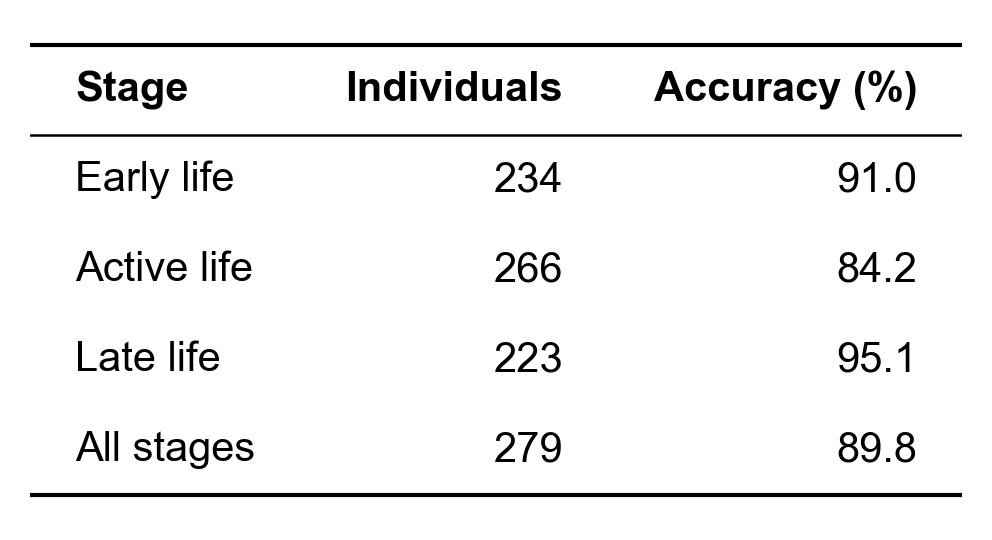

In [2]:
by_stage = accuracy(compared, "stage", "Stage").sort(pl.col("Stage").cast(pl.Enum(list(STAGES)))).with_columns(pl.col("Stage").replace(STAGES))
overall = accuracy(compared.with_columns(stage=pl.lit("All stages")), "stage", "Stage")
show_table(pl.concat([by_stage, overall]), decimals=1, font_size=10)

## Accuracy by notability

Famous: 10 Wikipedia editions or more; less known: fewer than 10.

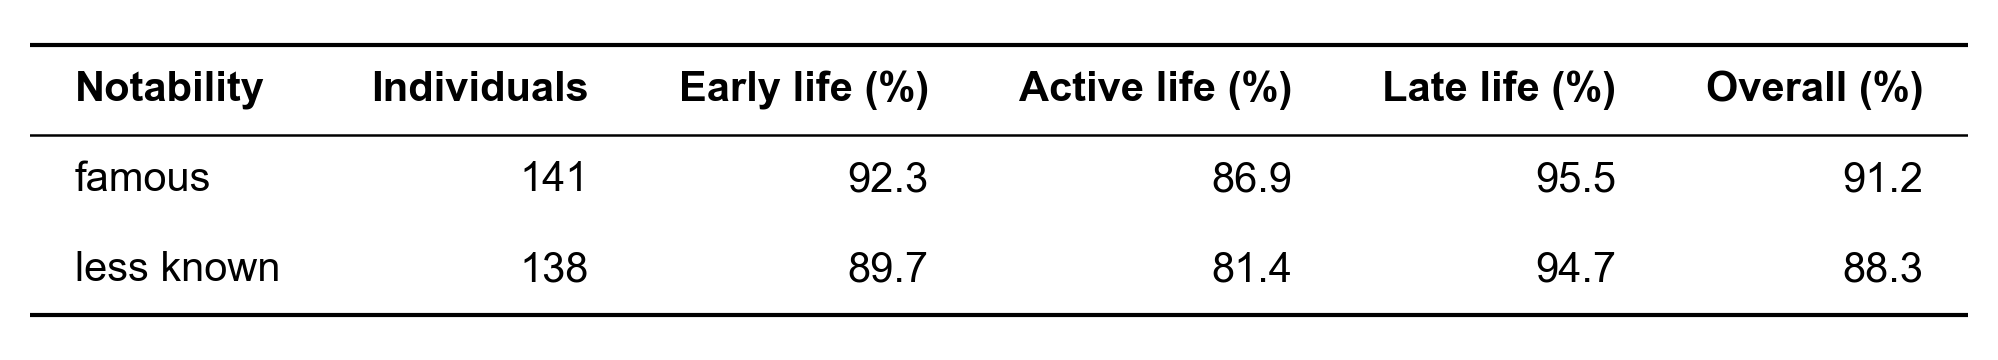

In [3]:
show_table(by_group("notability", "Notability").sort("Notability"), decimals=1, font_size=10)

## Accuracy by century of birth

Accuracy per stage and overall; a dash is a stage with no comparison in the century.

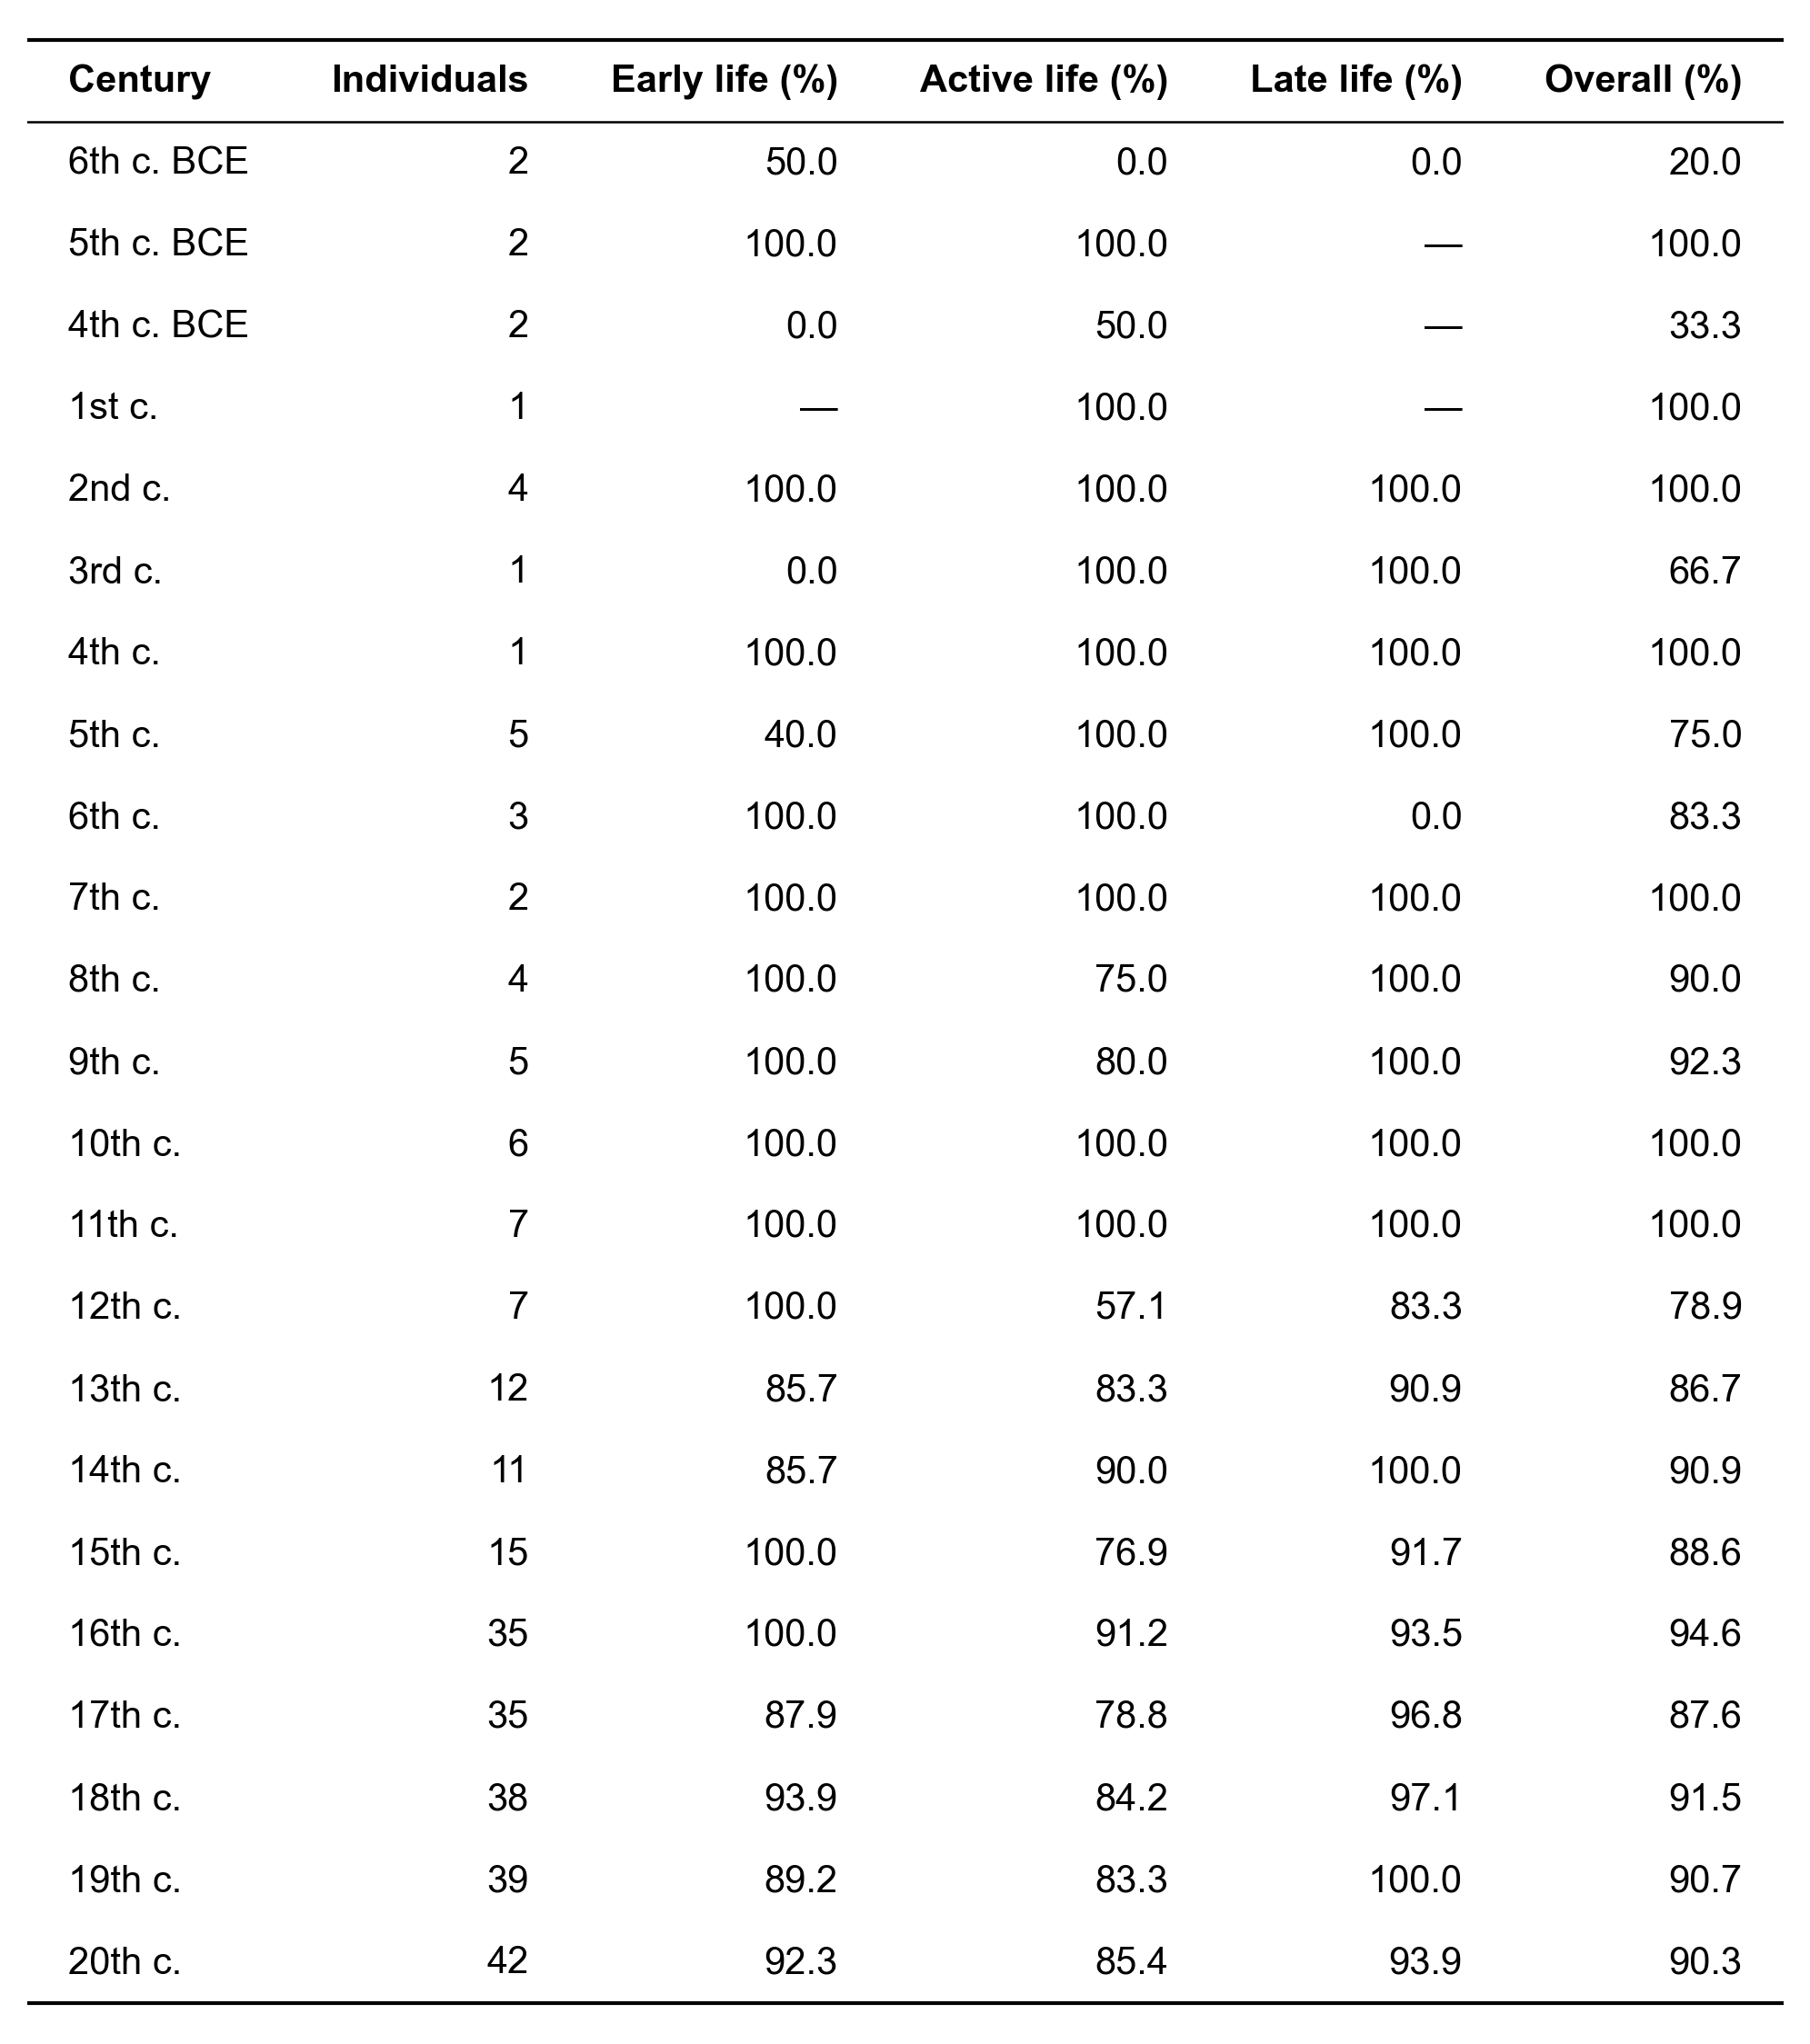

In [4]:
by_century = by_group("century", "Century").sort("Century").with_columns(pl.col("Century").map_elements(century_name, return_dtype=pl.String))
show_table(by_century, decimals=1, font_size=10)

## Accuracy by region

Accuracy per stage and overall; a dash is a stage with no comparison in the region. The Sub-Saharan Africa individual has no stage compared.

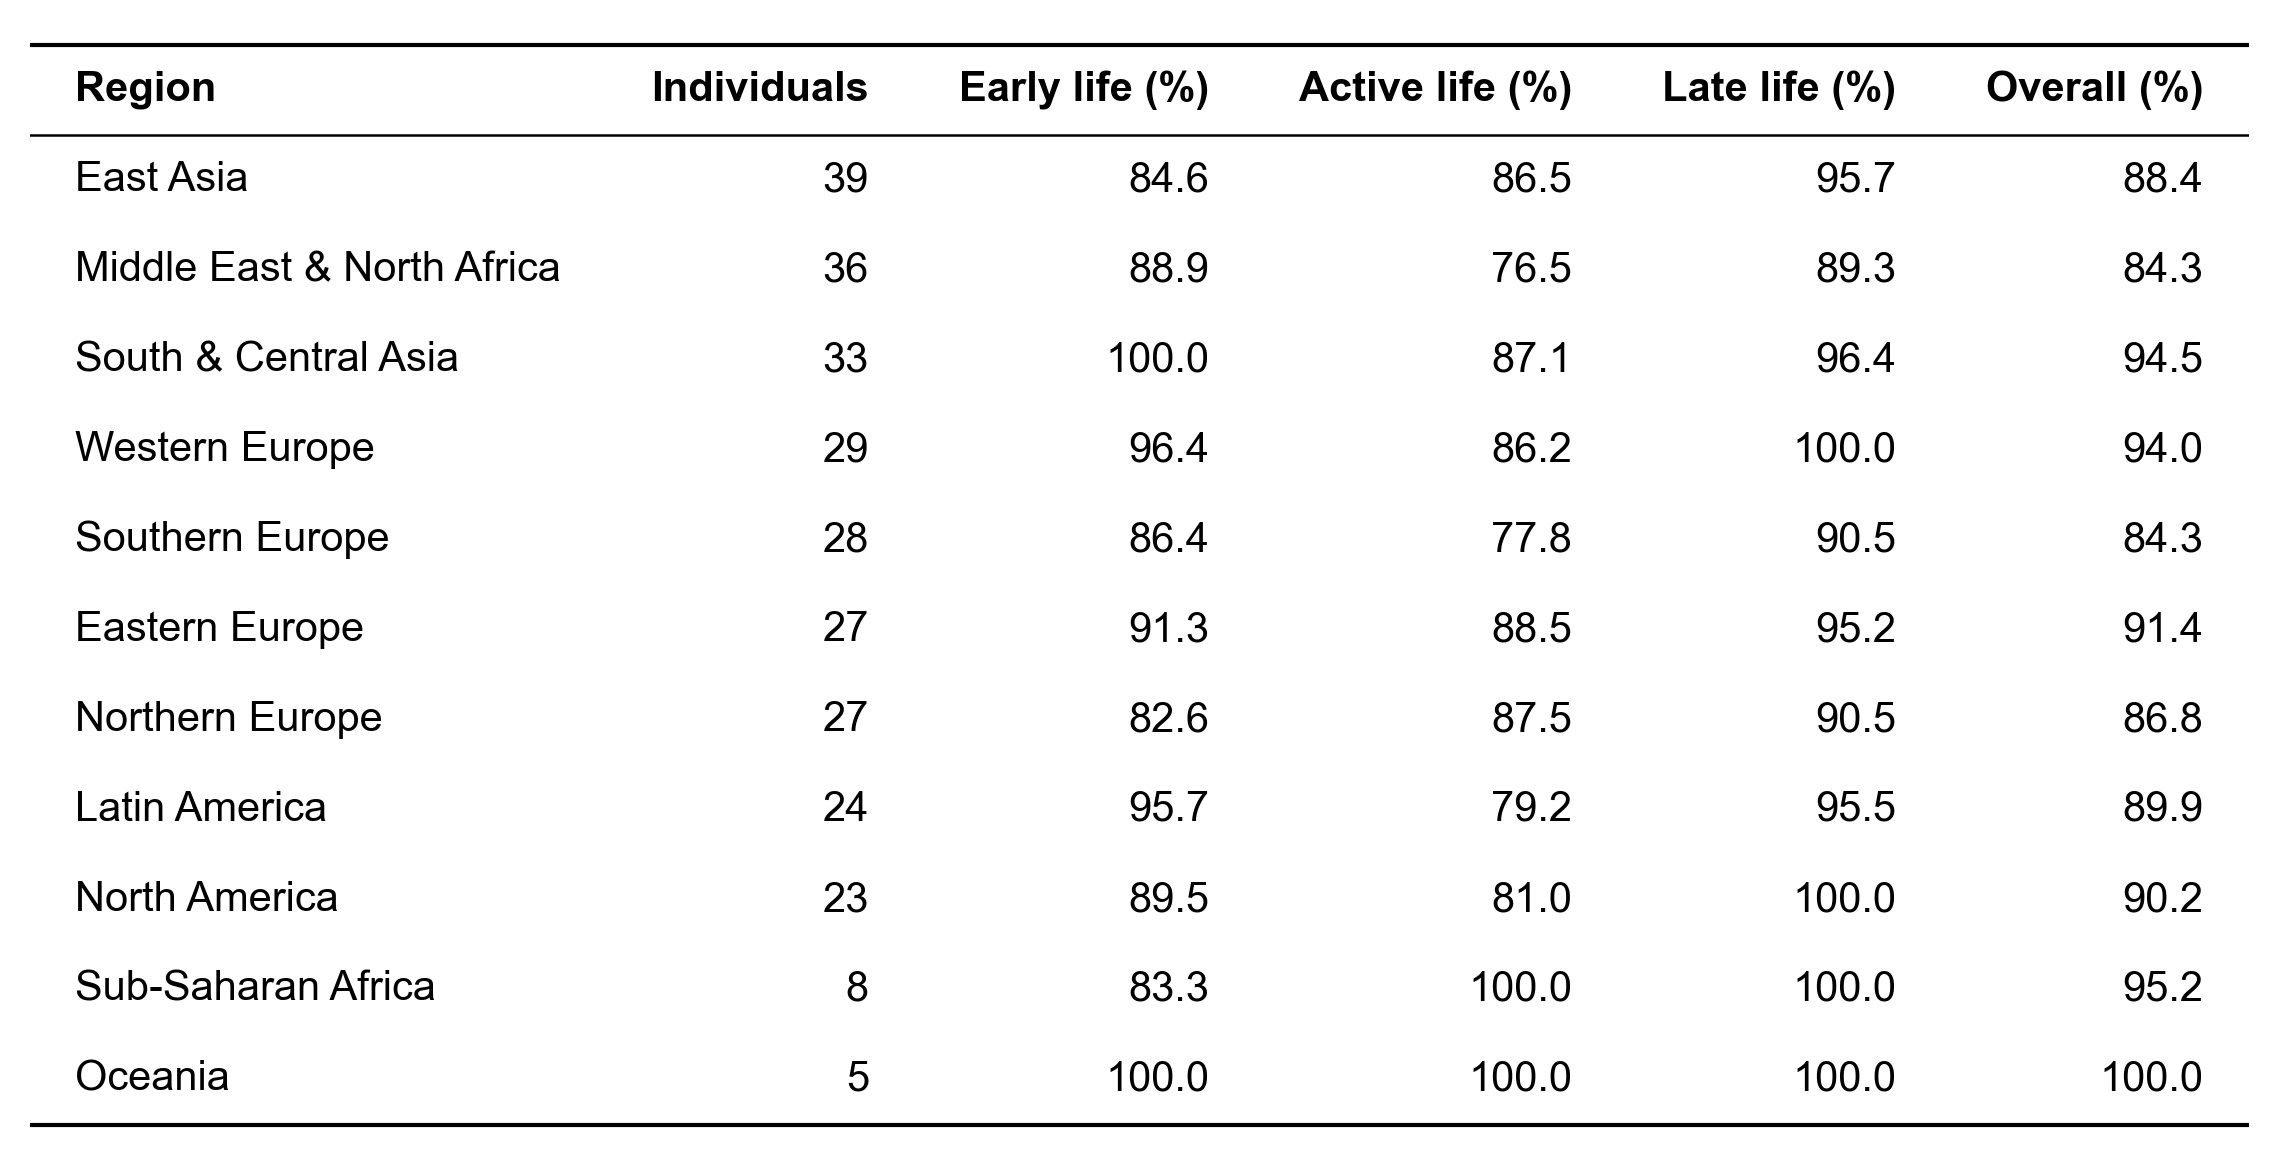

In [5]:
show_table(by_group("region", "Region").sort("Individuals", "Region", descending=[True, False]), decimals=1, font_size=10)

## Accuracy by region and century of birth

The table gives the active-stage accuracy for each region and century of birth, with the number of individuals compared in parentheses (a dash is no individual compared); the plot gives the overall accuracy (all stages).

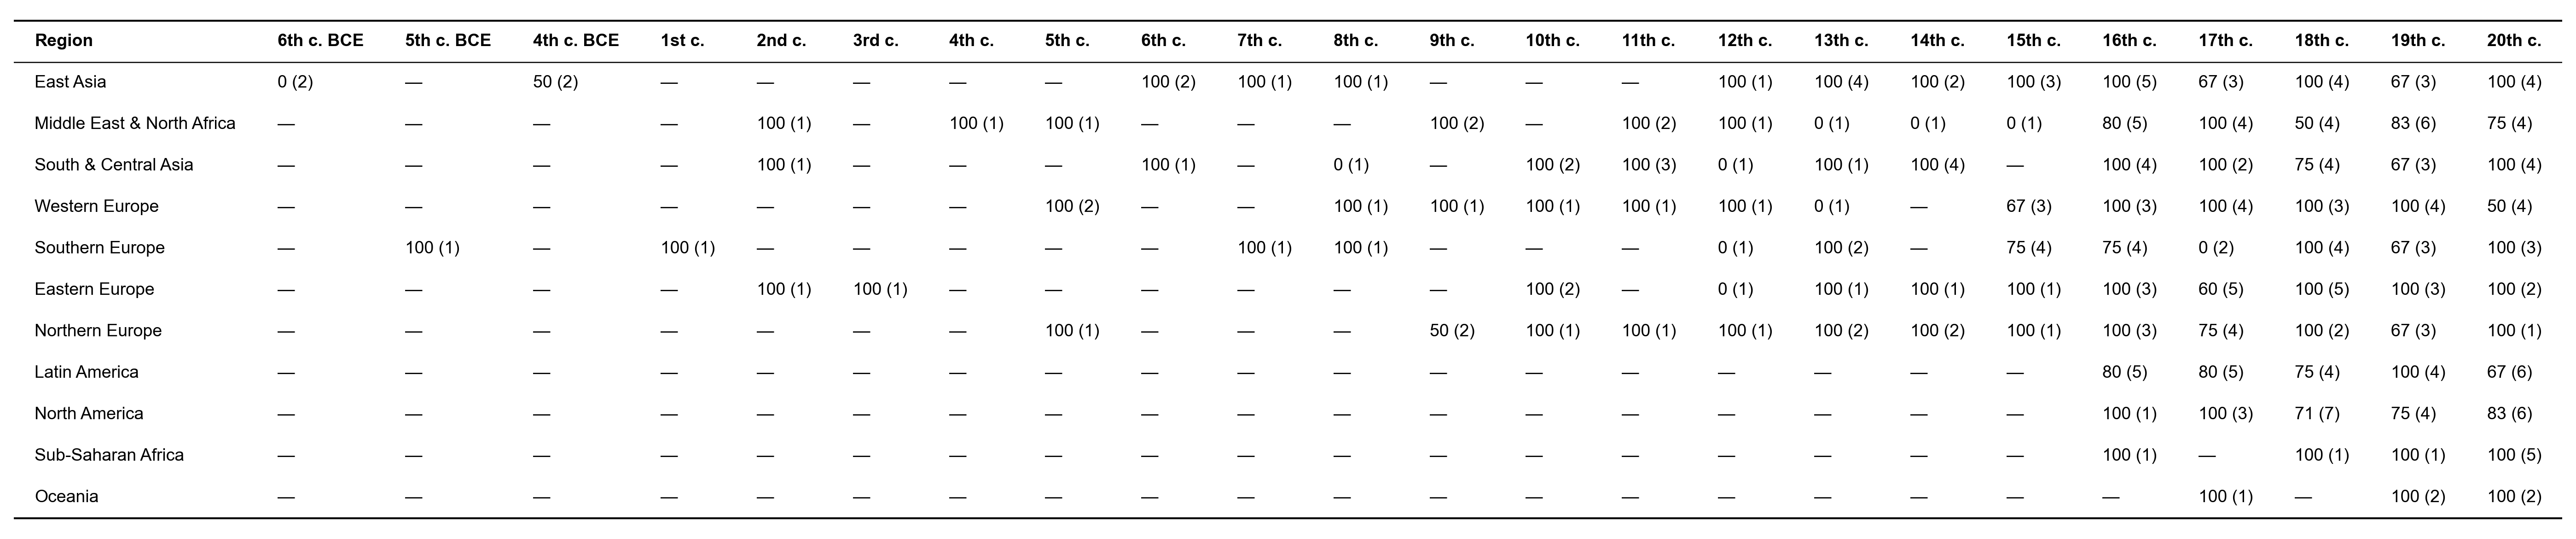

In [6]:
grid = (compared.group_by("region", "century").agg(Individuals=pl.col("qid").n_unique(), accuracy=(100 * pl.col("validated").mean()).round(1))
        .sort("century"))
centuries = grid["century"].unique().sort().to_list()
region_order = by_group("region", "Region").sort("Individuals", "Region", descending=[True, False])["Region"].to_list()
active = (compared.filter(pl.col("stage") == "active")
          .group_by("region", "century").agg(Individuals=pl.col("qid").n_unique(), accuracy=(100 * pl.col("validated").mean()).round(1)))
table = (active.with_columns(pl.col("century").map_elements(century_name, return_dtype=pl.String),
                           cell=pl.col("accuracy").round(0).cast(pl.Int64).cast(pl.String) + " (" + pl.col("Individuals").cast(pl.String) + ")")
         .pivot(on="century", index="region", values="cell")
         .with_columns(pl.col("region").cast(pl.Enum(region_order))).sort("region")
         .select(pl.col("region").cast(pl.String).alias("Region"), *[century_name(century) for century in centuries if century_name(century) in active["century"].map_elements(century_name, return_dtype=pl.String).to_list()]))
show_table(table, font_size=9)

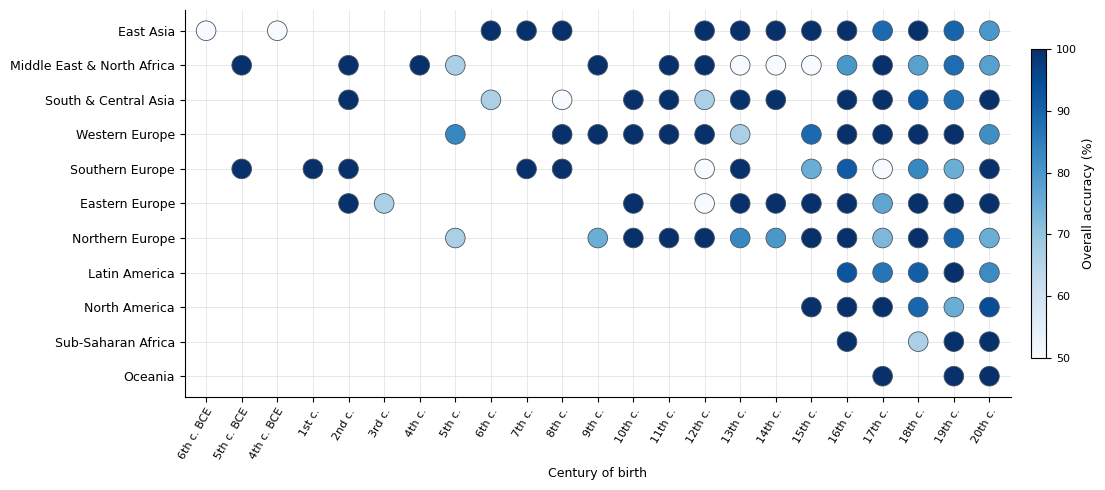

In [7]:
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize

points = grid.with_columns(x=pl.col("century").replace_strict({century: i for i, century in enumerate(centuries)}),
                           y=pl.col("region").replace_strict({region: i for i, region in enumerate(region_order)}))
norm = Normalize(vmin=50, vmax=100)
fig, ax = plt.subplots(figsize=(12, 5))
dots = ax.scatter(points["x"], points["y"], s=200, c=points["accuracy"], cmap="Blues", norm=norm,
                  edgecolors="#4a5560", linewidths=0.6, zorder=3)
ax.set_xticks(range(len(centuries)), [century_name(century) for century in centuries], fontsize=8, rotation=60, ha="right", rotation_mode="anchor")
ax.set_yticks(range(len(region_order)), region_order, fontsize=9)
ax.invert_yaxis()
ax.set_xlim(-0.6, len(centuries) - 0.4)
ax.set_ylim(len(region_order) - 0.4, -0.6)
ax.grid(color="#e1e5e9", linewidth=0.6, zorder=0)
ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
ax.set_xlabel("Century of birth", fontsize=9)
colorbar = fig.colorbar(dots, ax=ax, pad=0.02, shrink=0.8)
colorbar.set_label("Overall accuracy (%)", fontsize=9)
colorbar.ax.tick_params(labelsize=8)
fig.tight_layout()
plt.show()